# סיווג אוטומטי של משלחי יד — מטלת מדען נתונים
**הלשכה המרכזית לסטטיסטיקה | הדגמה על נתונים סינתטיים**

מטרת המחברת היא לנתח לעומק את נתוני הסקר והמטא-דאטה, לטפל במפורש בכל אחת מ-18 העמודות, לאמן מודל AI לחיזוי `SemelMishlachSofi` ולספק תוצאות חיזוי. הקוד מיועד להרצה מלאה ב-Google Colab, באמצעות טעינת קובץ Excel ישירות ממאגר GitHub ציבורי, ללא הרשאות Google Drive או מפתחות SSH.

**מקור נתונים:** [`DUMMY_DATASET.xlsx`](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx) מתוך מאגר GitHub, הכולל `Survey Dataset` ו-`Metadata`. מסמך המטלה נמצא בתיקיית `Assignment` ב-Drive. המקור הוא סימולציה, והוא כולל 200 רשומות. לפי מטלת המיון, כ-90% מהסימולים הידניים אושרו כתקינים במדגם, וקודים המכילים X הם סימולים חלקיים. **למדדי החיזוי על הסימולציה אין משמעות כמדדי ביצועי אמת.**

[Notebook ב-GitHub](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/survey_occupation_classification.ipynb) | [פתח ב-Colab](https://colab.research.google.com/github/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/survey_occupation_classification.ipynb)

**מפת העבודה:** הגדרות שדות ← טעינה מבוקרת ← בדיקות לכל שדה ← גרפים לכל שדה ← איכות תוויות ותלות בין שדות ← בניית מאפיינים ← הפרדת קבוצות ← אימון והערכת מודל ← חיזויים ← המלצות להטמעה.

In [1]:
import hashlib, re
from io import BytesIO
from urllib.request import urlopen
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
SEED = 42
np.random.seed(SEED)
print('scikit-learn:', sklearn.__version__, '| pandas:', pd.__version__)

scikit-learn: 1.8.0 | pandas: 2.2.3


## 1. טעינה ישירה של נתוני המקור והגדרות השדות
המחברת מורידה את קובץ ה-Excel המקורי מתוך GitHub הציבורי באמצעות HTTPS וקוראת את שני הגיליונות: `Survey Dataset` ו-`Metadata`. אין העתק של הנתונים או של מילון השדות בתוך המחברת, ואין צורך בהעלאת קובץ ידנית או במפתח SSH.

בגיליון `Survey Dataset` קיימת שורת סיכום נוספת ללא `ID`; היא אינה רשומת משתתף ולכן מופרדת מ-200 רשומות הסקר. קודי הסימול נטענים כמחרוזות כדי לשמר קודי `X` ואת המשמעות הקטגוריאלית, ומילון השדות מתקבל ישירות מארבע העמודות הראשונות ב-`Metadata`.

**מקור:** [Excel ב-GitHub](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx). כל ניתוח והתרשימים להלן מבוססים על קובץ זה בזמן הרצת המחברת.

**בדיקת הרצה שמורה:** תוצרי הריצה השמורים במחברת הופקו מול קובץ מקומי שזהה בביטים לקובץ שב-GitHub (Git blob SHA: `daee1a2e6d85f7f9f76f2fde767b3fe835a0b119`). בהרצה ב-Colab, הקובץ נטען ישירות מכתובת GitHub.


In [2]:
# The dataset is public; HTTPS is sufficient. No SSH key or GitHub token is needed.
DATASET_URL = (
    "https://raw.githubusercontent.com/shulruferor-sudo/Advance-Data-Science/"
    "main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx"
)
with urlopen(DATASET_URL, timeout=60) as response:
    workbook_bytes = response.read()

if not workbook_bytes.startswith(b"PK"):
    raise ValueError("GitHub response is not an Excel .xlsx file")
SOURCE_SHA256 = hashlib.sha256(workbook_bytes).hexdigest()

# Read the original workbook, without copying its participant data into Python source.
with pd.ExcelFile(BytesIO(workbook_bytes), engine="openpyxl") as excel:
    required_sheets = {"Survey Dataset", "Metadata"}
    if not required_sheets.issubset(set(excel.sheet_names)):
        raise ValueError(f"Workbook sheets differ from the assignment: {excel.sheet_names}")
    raw_survey = pd.read_excel(
        excel, sheet_name="Survey Dataset",
        dtype={"SemelAnafSofi": "string", "SemelMishlachSofi": "string"},
    )
    # Metadata contains formatting extending to Excel's last column.
    # Only the four actual definition columns are relevant.
    metadata = pd.read_excel(
        excel, sheet_name="Metadata", usecols="A:D",
        dtype={"משתנה": "string", "הסבר": "string", "פורמט": "string", "ערכים אפשריים": "string"},
    )

# Exclude the non-participant summary row, preserving the source workbook as read-only.
summary_rows = raw_survey.loc[raw_survey["ID"].isna()].copy()
survey = raw_survey.loc[raw_survey["ID"].notna()].copy()
survey["ID"] = survey["ID"].astype("int64")
for code_column in ("SemelAnafSofi", "SemelMishlachSofi"):
    survey[code_column] = survey[code_column].astype("string").str.strip()

metadata = metadata.rename(columns={
    "משתנה": "field", "הסבר": "description",
    "פורמט": "dtype", "ערכים אפשריים": "domain",
})
metadata = metadata.dropna(subset=["field"]).copy()
metadata["field"] = metadata["field"].str.strip()
if metadata["field"].duplicated().any():
    raise ValueError("Duplicate field definitions in Metadata")

def nullable_text(value):
    return str(value).strip() if pd.notna(value) else None

FIELD_METADATA = {
    row.field: {
        "description": nullable_text(row.description),
        "dtype": nullable_text(row.dtype),
        "domain": nullable_text(row.domain),
    }
    for row in metadata.itertuples(index=False)
}

COLUMN_RULES = {'ID': ('מזהה רשומה', 'בקרה בלבד', 'בדיקת ייחודיות ושימוש לקישור תוצאות', 'מספר רץ אינו מזהה נסקר או מאפיין מקצועי'), 'YeshuvAvoda': ('יישוב עבודה', 'בקרה בלבד', 'בדיקת פיזור ומחרוזות; לא מוכנס למודל', 'פרוקסי גאוגרפי ושונות בין יישובים'), 'ShemAvoda': ('שם מקום העבודה', 'בקרה וקיבוץ', 'נרמול רווחים לשם קבוצת כפילויות; לא מאפיין למודל', 'סיכון שינון מקום עבודה במקום כישורי עיסוק'), 'SugAvoda': ('פעילות מקום העבודה', 'טקסט למודל', 'TF-IDF תווים, עם קידומת שם השדה וסמן חסר', '25 חסרים; ההקשר העסקי שונה ממטלות התפקיד'), 'ShemMachlaka': ('אגף/מחלקה', 'טקסט למודל', 'TF-IDF תווים עם קידומת שדה וסמן חסר', '64 חסרים; אינו זהה לשם המעסיק'), 'SugMachlaka': ('פעילות מחלקה', 'טקסט למודל', 'TF-IDF תווים; ״כנ״ל״ מסומן כלא מפוענח', '134 חסרים; 8 ערכי ״כנ״ל״'), 'EzoAvoda': ('עבודה בפועל', 'טקסט למודל', 'TF-IDF תווים עם קידומת שדה וסמן חסר', '7 חסרים; תיאור פעולה ישיר'), 'TeurPeula': ('פעולות עיקריות', 'טקסט למודל', 'TF-IDF תווים; ״כנ״ל״ נשמר כסמן לא מפוענח', '136 חסרים; 12 ״כנ״ל״'), 'TeurTafkid': ('תואר משרה', 'טקסט למודל', 'TF-IDF תווים; ״כנ״ל״ ו-0 מסומנים כחריגה', '172 חסרים; 4 ״כנ״ל״; 0 טקסטואלי יחיד'), 'MenahelEtMi': ('ניהול עובדים ומנהלים', 'קטגוריה למודל', '1/2/3 נומינלי; חסר אינו ״לא מנהל״', '168 חסרים; אין קטגוריית 0 מוגדרת'), 'MaamadAvoda': ('מעמד עבודה', 'קטגוריה למודל', '1–7 נומינלי; חסר נפרד', '2 חסרים; מגדיר תחולה של MakorSachar'), 'MakorSachar': ('מקור שכר', 'קטגוריה מותנית', 'אם מעמד 1/5: 1–4; אחרת not_applicable; ערך מקור נשמר לאבחון', '9 ערכים שמולאו מחוץ לתנאי המוצהר ב-Metadata'), 'TeudaGvoha': ('התואר/תעודה הגבוהים ביותר', 'קטגוריה למודל', '1–9 one-hot נומינלי, כולל חריגים 8/9', '2 חסרים; קודים אינם מרחק מספרי'), 'shnotlimud': ('שנות לימוד', 'מספרי למודל', 'חציון האימון בלבד ו-StandardScaler באימון', '2 חסרים; 7–22 בנתונים'), 'Gil': ('גיל', 'בקרה בלבד', 'בדיקת תחום וריכוז; לא במודל הראשי', 'פרוקסי רגיש אפשרי; 2 חסרים; 22–78'), 'TarichHathala': ('תאריך תחילת תפקיד', 'בקרה בלבד', 'פריסת תאריכים; אין חישוב ותק ללא מועד סקר', '42 תאריכים ייחודיים בטווח 1999–2026'), 'SemelAnafSofi': ('סמל ענף כלכלי סופי', 'בקרה בלבד', 'שמור מחרוזת; בדוק X ואורך; אל תשלים אפסים', 'זמינות בזמן חיזוי לא מוכחת; 9 X; 5 קודים מספריים תלת־ספרתיים'), 'SemelMishlachSofi': ('סמל משלח יד סופי', 'משתנה מטרה', 'מחרוזת 4 תווים; 9 קודים X מסוננים מ-fit; הצעת סקירה אנושית', '62 קודים נצפים; תיעוד השדה נטען ישירות מחוצץ Metadata')}

assert survey.shape == (200, 18) and survey["ID"].nunique() == 200
assert survey["SemelMishlachSofi"].notna().all()
assert set(FIELD_METADATA) == set(survey.columns) == set(COLUMN_RULES)
print("קובץ Excel נטען משני הגיליונות, תוך שמירה על נתוני המקור")
print("רשומות:", len(survey), "| שדות:", survey.shape[1],
      "| שורות סיכום שהוחרגו:", len(summary_rows),
      "| הגדרות במטא-דאטה:", len(metadata),
      "| SHA-256:", SOURCE_SHA256[:16])
display(survey.head(5))
display(metadata.head(5))


קובץ Excel נטען משני הגיליונות, תוך שמירה על נתוני המקור
רשומות: 200 | שדות: 18 | שורות סיכום שהוחרגו: 1 | הגדרות במטא-דאטה: 18 | SHA-256: e1e7f391c0675dd1


,ID,YeshuvAvoda,ShemAvoda,SugAvoda,ShemMachlaka,SugMachlaka,EzoAvoda,TeurPeula,TeurTafkid,MenahelEtMi,MaamadAvoda,MakorSachar,TeudaGvoha,shnotlimud,Gil,TarichHathala,SemelAnafSofi,SemelMishlachSofi
0,1,ירושלים,"למ""ס","איסוף, עיבוד ופרסום נתונים",מיקרו כלכלה,טיפול בנתוני מיקרו,סגן מנהל אגף,"כנ""ל",סגן מנהל אגף,3.0,1.0,1.0,6.0,22.0,55.0,2020-06-15,8411,2120
1,2,ירושלים,בית חולים הדסה עין כרם,טיפול בחולים,רדיואתרפיה,טיפול בחולי סרטן,טכנאית רדיותרפיה,"כנ""ל","כנ""ל",NaN,1.0,1.0,6.0,22.0,55.0,2022-07-01,8610,3311
2,3,באר שבע,קריית הממשלה,מתן שירות למשתמשים באתר GOV,תמיכה בלקוחות,"כנ""ל",נותנת תמיכה ללקוחות שמבקשים עזרה,מסבירה איך להשתמש בשירותים ממשלתיים באתר האינטרנט,NaN,NaN,1.0,1.0,5.0,15.0,29.0,2021-06-06,8411,3512
3,4,תל אביב,משרד החינוך,בית ספר יסודי,שמירה,NaN,שומר בבית הספר,NaN,NaN,NaN,1.0,2.0,3.0,12.0,48.0,2024-07-01,8010,5414
4,5,תל אביב,אמיר כהן,מטפל בקשיש במשפחה,NaN,NaN,מטפל בקשיש,"נותן אוכל, עוזר בניקיון בית, עוזר להתרחץ",NaN,NaN,1.0,1.0,4.0,14.0,42.0,2010-01-11,XXXX,5322


,field,description,dtype,domain
0,ID,מספר רץ,INTEGER,<NA>
1,YeshuvAvoda,שם יישוב עבודה,TEXT,<NA>
2,ShemAvoda,שם מקום העבודה שלך,TEXT,<NA>
3,SugAvoda,הפעילות העיקרית של מקום העבודה,TEXT,<NA>
4,ShemMachlaka,אגף או מחלקה שהנסקר עובד,TEXT,<NA>


## 2. חוזה טיפול פרטני לכל 18 השדות
הטבלה מציגה לכל שדה את התיאור הרשמי, הפורמט, תחום הקודים המוצהר, תפקידו במודל, דרך הטיפול וסיכון המידע. גם `SemelMishlachSofi` מופיע בגיליון `Metadata` ומוגדר שם כמשתנה המטרה. ההסברים, הפורמטים והקודים האפשריים נקראים ישירות מגיליון זה, וההחלטות על הטיפול בכל שדה מפורטות בנפרד.

**עקרונות חשובים:** `MenahelEtMi` חסר אינו ״לא מנהל״; `MaamadAvoda` קובע האם יש למלא `MakorSachar`; הקודים של `TeudaGvoha` הם קטגוריות ולא מספר מדיד; `SemelAnafSofi` הוא סמל סופי שזמינותו בזמן החיזוי לא אומתה; `TarichHathala` אינו מועד השלמת הסקר ולכן אין להמירו לוותק על בסיס מועד נוכחי.

In [3]:
dictionary = pd.DataFrame([{'field':k, 'source_description':FIELD_METADATA[k]['description'],
 'format':FIELD_METADATA[k]['dtype'],
 'allowed_values':FIELD_METADATA[k]['domain'] or 'not specified',
 'role': COLUMN_RULES[k][1], 'handling':COLUMN_RULES[k][2],
 'risk_and_rationale': COLUMN_RULES[k][3]} for k in survey.columns])
display(dictionary)

,field,source_description,format,allowed_values,role,handling,risk_and_rationale
0,ID,מספר רץ,INTEGER,not specified,בקרה בלבד,בדיקת ייחודיות ושימוש לקישור תוצאות,מספר רץ אינו מזהה נסקר או מאפיין מקצועי
1,YeshuvAvoda,שם יישוב עבודה,TEXT,not specified,בקרה בלבד,בדיקת פיזור ומחרוזות; לא מוכנס למודל,פרוקסי גאוגרפי ושונות בין יישובים
2,ShemAvoda,שם מקום העבודה שלך,TEXT,not specified,בקרה וקיבוץ,נרמול רווחים לשם קבוצת כפילויות; לא מאפיין למודל,סיכון שינון מקום עבודה במקום כישורי עיסוק
3,SugAvoda,הפעילות העיקרית של מקום העבודה,TEXT,not specified,טקסט למודל,"TF-IDF תווים, עם קידומת שם השדה וסמן חסר",25 חסרים; ההקשר העסקי שונה ממטלות התפקיד
4,ShemMachlaka,אגף או מחלקה שהנסקר עובד,TEXT,not specified,טקסט למודל,TF-IDF תווים עם קידומת שדה וסמן חסר,64 חסרים; אינו זהה לשם המעסיק
5,SugMachlaka,הפעילות העיקרית של האגף או המחלקה שהנסקר עובד,TEXT,not specified,טקסט למודל,TF-IDF תווים; ״כנ״ל״ מסומן כלא מפוענח,134 חסרים; 8 ערכי ״כנ״ל״
6,EzoAvoda,עבודה שהנסקר עושה במקום עבודה זה,TEXT,not specified,טקסט למודל,TF-IDF תווים עם קידומת שדה וסמן חסר,7 חסרים; תיאור פעולה ישיר
7,TeurPeula,הפעולות העיקריות שהנסקר עושה במקום עבודה,TEXT,not specified,טקסט למודל,TF-IDF תווים; ״כנ״ל״ נשמר כסמן לא מפוענח,136 חסרים; 12 ״כנ״ל״
8,TeurTafkid,מהו תואר המשרה של הנסקר במקום עבודה זה (במידה...,TEXT,not specified,טקסט למודל,TF-IDF תווים; ״כנ״ל״ ו-0 מסומנים כחריגה,172 חסרים; 4 ״כנ״ל״; 0 טקסטואלי יחיד
9,MenahelEtMi,האם הנסקר מנהל או ממונה על עובדים אחרים?,INTEGER,1. מנהל עובדים\n2. מנהל מנהלים\n3. מנהל עובדים...,קטגוריה למודל,1/2/3 נומינלי; חסר אינו ״לא מנהל״,168 חסרים; אין קטגוריית 0 מוגדרת


## 3. פרופיל כל העמודות — שלמות, שונות וערכים שכיחים
מדדי השלמות מחושבים מתוך מקור הנתונים בלבד. התוצאה כוללת את כל 18 העמודות, גם את אלה שאינן נכנסות למודל. השכיחויות מתייחסות לערכים המקוריים אחרי הצגה עקבית של רווחים וחסרים, ולא להשלמה שהושתתה על נתוני הבדיקה.

,field,missing_n,missing_pct,n_distinct_non_missing,most_common,model_role
0,ID,0,0.0,200,"{'1': 1, '2': 1, '3': 1}",בקרה בלבד
1,YeshuvAvoda,0,0.0,21,"{'תל אביב': 35, 'ירושלים': 21, 'חיפה': 19}",בקרה בלבד
2,ShemAvoda,0,0.0,82,"{'מסעדה': 10, 'משרד החינוך': 9, 'בנק לאומי': 7}",בקרה וקיבוץ
3,SugAvoda,25,12.5,78,"{'[MISSING]': 25, 'מסעדה': 7, 'בית ספר יסודי': 7}",טקסט למודל
4,ShemMachlaka,64,32.0,61,"{'[MISSING]': 64, 'שמירה': 7, 'תמיכה בלקוחות': 6}",טקסט למודל
5,SugMachlaka,134,67.0,35,"{'[MISSING]': 134, 'כנ""ל': 8, 'טיפול בחולי סרט...",טקסט למודל
6,EzoAvoda,7,3.5,84,"{'שומר בבית הספר': 7, '[MISSING]': 7, 'טבח': 7}",טקסט למודל
7,TeurPeula,136,68.0,32,"{'[MISSING]': 136, 'כנ""ל': 12, ""מפקח על תהליך ...",טקסט למודל
8,TeurTafkid,172,86.0,16,"{'[MISSING]': 172, 'כלכלן': 6, 'כנ""ל': 4}",טקסט למודל
9,MenahelEtMi,168,84.0,3,"{'[MISSING]': 168, '3.0': 13, '2.0': 11}",קטגוריה למודל


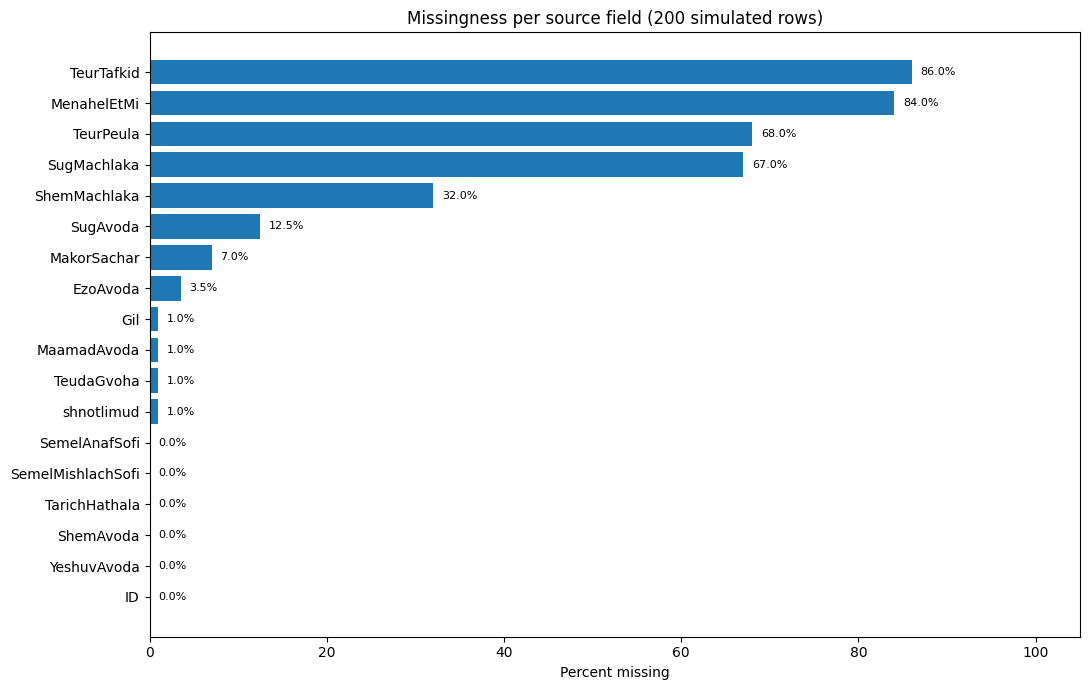

In [4]:
def missing(v):
    return pd.isna(v) or (isinstance(v, str) and not v.strip())

def categorical_values(column):
    return survey[column].astype('string').str.strip().fillna('[MISSING]').replace('', '[MISSING]')

column_audit = pd.DataFrame([
    {'field':c, 'missing_n':int(survey[c].map(missing).sum()),
     'missing_pct':round(100*survey[c].map(missing).mean(),1),
     'n_distinct_non_missing':int(categorical_values(c).loc[lambda x:x!='[MISSING]'].nunique()),
     'most_common':str(categorical_values(c).value_counts().head(3).to_dict()),
     'model_role':COLUMN_RULES[c][1]}
    for c in survey.columns
])
assert len(column_audit)==18
assert column_audit.set_index('field').loc['MenahelEtMi','missing_n'] == 168
assert column_audit.set_index('field').loc['TeurTafkid','missing_n'] == 172
display(column_audit)
fig, ax=plt.subplots(figsize=(11,7))
d = column_audit.sort_values('missing_pct')
ax.barh(d['field'],d['missing_pct'])
for j,val in enumerate(d['missing_pct']):ax.text(val+1,j,f'{val:.1f}%',va='center',fontsize=8)
ax.set(xlim=(0,105),xlabel='Percent missing',title='Missingness per source field (200 simulated rows)')
plt.tight_layout();plt.show()

## 4. תרשימים ייעודיים לכל עמודה
כל אחת מ-18 העמודות מוצגת בתרשים המתאים לסוג הערכים שלה: מזהה לפי סדר, תאריכים לפי שנות התחלה, שדות מספריים בהיסטוגרמה ושדות קטגוריאליים/טקסטואליים בהתפלגות ששת הערכים הנפוצים. כיוון שמשתני טקסט מכילים עברית, התרשים מציג דירוג מספרי ו**טבלת מקרא עם הערך העברי המקורי** כדי להימנע ממיקום אותיות שגוי ב-Matplotlib. אין פירוש קוד כתיאור מקצוע ללא מידע מהמקור.

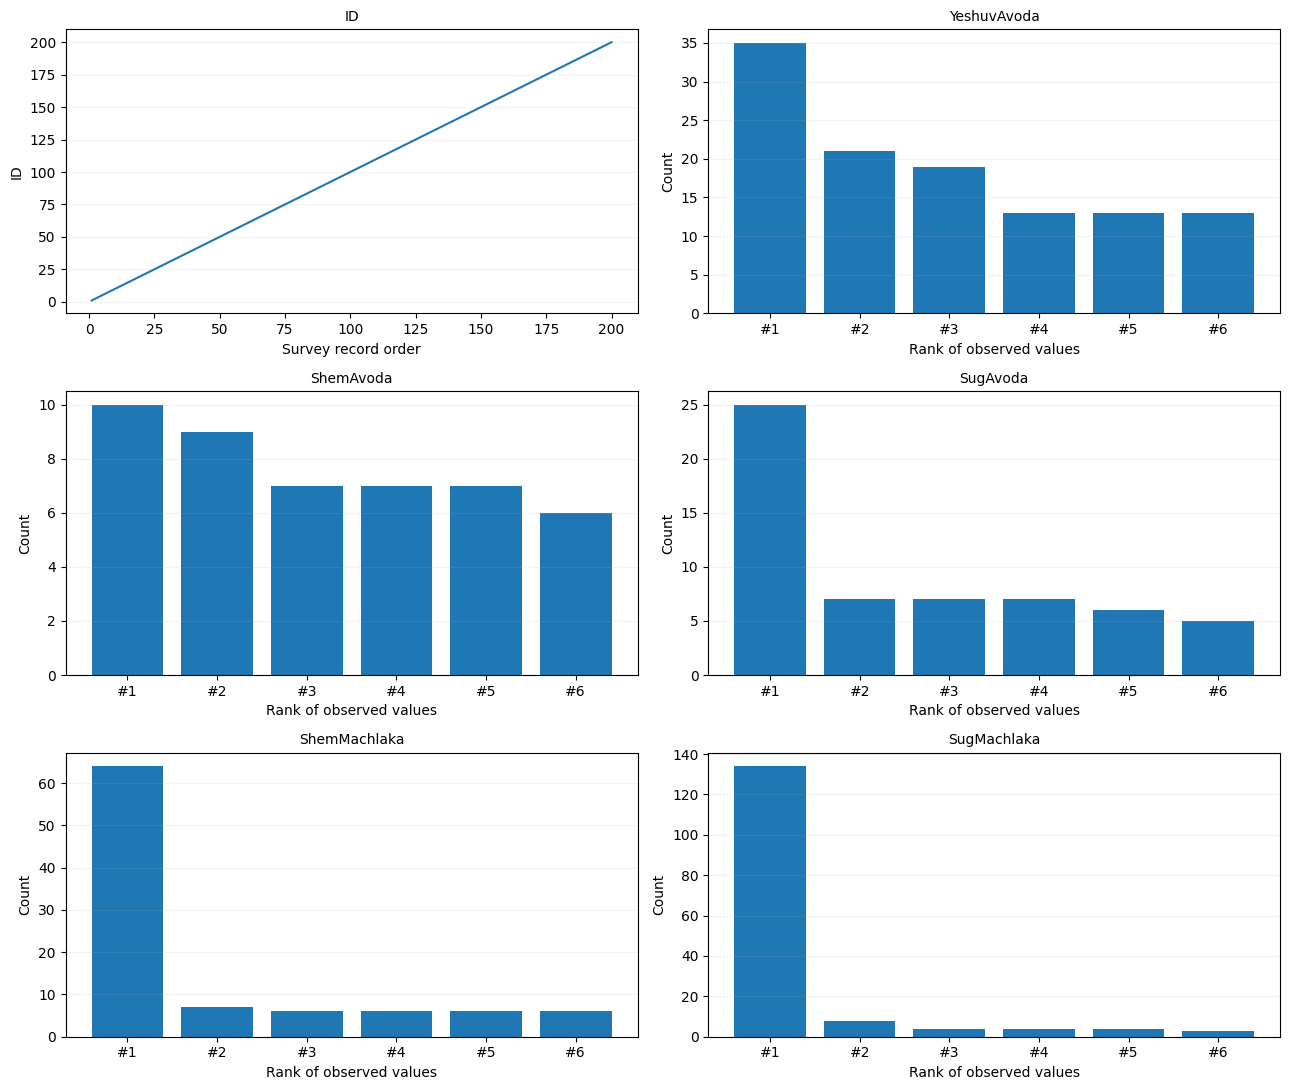

Original values for the six ranked charts:
ID  ::  #1: 1 (1) | #2: 2 (1) | #3: 3 (1) | #4: 4 (1) | #5: 5 (1) | #6: 6 (1)
YeshuvAvoda  ::  #1: תל אביב (35) | #2: ירושלים (21) | #3: חיפה (19) | #4: רעננה (13) | #5: הרצליה (13) | #6: אילת (13)
ShemAvoda  ::  #1: מסעדה (10) | #2: משרד החינוך (9) | #3: בנק לאומי (7) | #4: משטרה (7) | #5: בית ספר תיכון (7) | #6: סופר פארם (6)
SugAvoda  ::  #1: [MISSING] (25) | #2: מסעדה (7) | #3: בית ספר יסודי (7) | #4: חנות למכירת בגדים (7) | #5: אירוח (6) | #6: מכירת קוסמטיקה (5)
ShemMachlaka  ::  #1: [MISSING] (64) | #2: שמירה (7) | #3: תמיכה בלקוחות (6) | #4: קוסמטיקה וטיפוח (6) | #5: משק (6) | #6: עובד ניקיון (6)
SugMachlaka  ::  #1: [MISSING] (134) | #2: כנ"ל (8) | #3: טיפול בחולי סרטן (4) | #4: טיפול באנשים עם בעיות (4) | #5: משחק (4) | #6: אריזה (3)


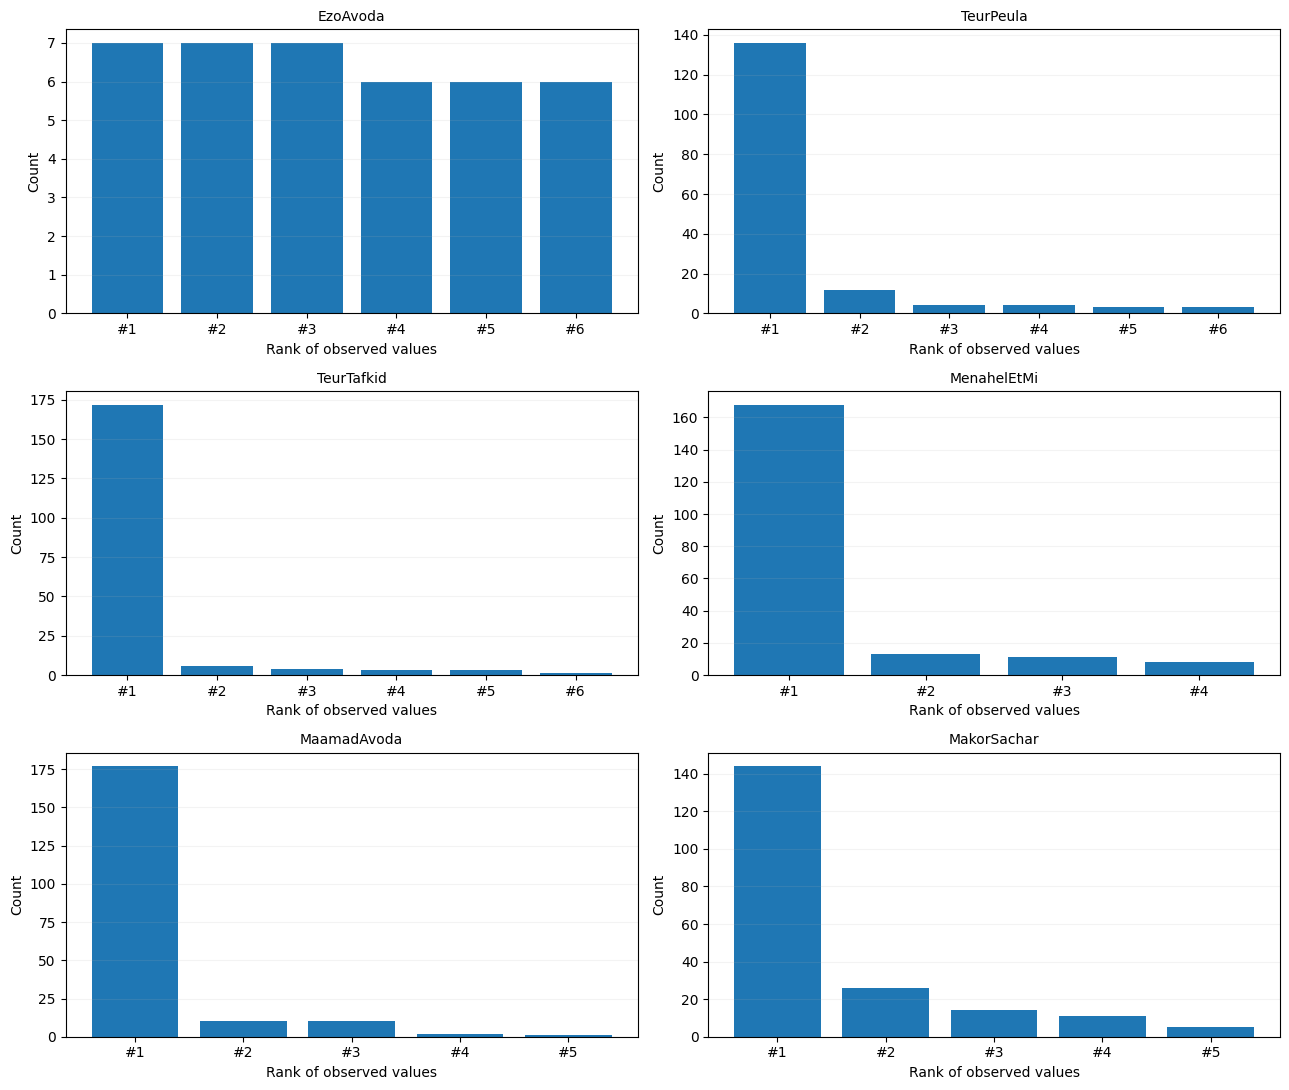

Original values for the six ranked charts:
EzoAvoda  ::  #1: שומר בבית הספר (7) | #2: [MISSING] (7) | #3: טבח (7) | #4: קוסמטיקאית (6) | #5: מנקה בית ספר אחרי הלימודים (6) | #6: מוכרת (6)
TeurPeula  ::  #1: [MISSING] (136) | #2: כנ"ל (12) | #3: מפקח על תהליך ייצור צ'יפים (4) | #4: מסבירה לאנשים לגבי מוצרים של חברת LOREAL (4) | #5: נותן תמיכה לעובדים בבנק ופוטר בעיות תקשורת (3) | #6: עוזר לחשמלאי (3)
TeurTafkid  ::  #1: [MISSING] (172) | #2: כלכלן (6) | #3: כנ"ל (4) | #4: סגן מנהל אגף (3) | #5: טכנאי מחשבים (3) | #6: 0 (1)
MenahelEtMi  ::  #1: [MISSING] (168) | #2: 3.0 (13) | #3: 2.0 (11) | #4: 1.0 (8)
MaamadAvoda  ::  #1: 1.0 (177) | #2: 4.0 (10) | #3: 6.0 (10) | #4: [MISSING] (2) | #5: 2.0 (1)
MakorSachar  ::  #1: 1.0 (144) | #2: 2.0 (26) | #3: [MISSING] (14) | #4: 3.0 (11) | #5: 4.0 (5)


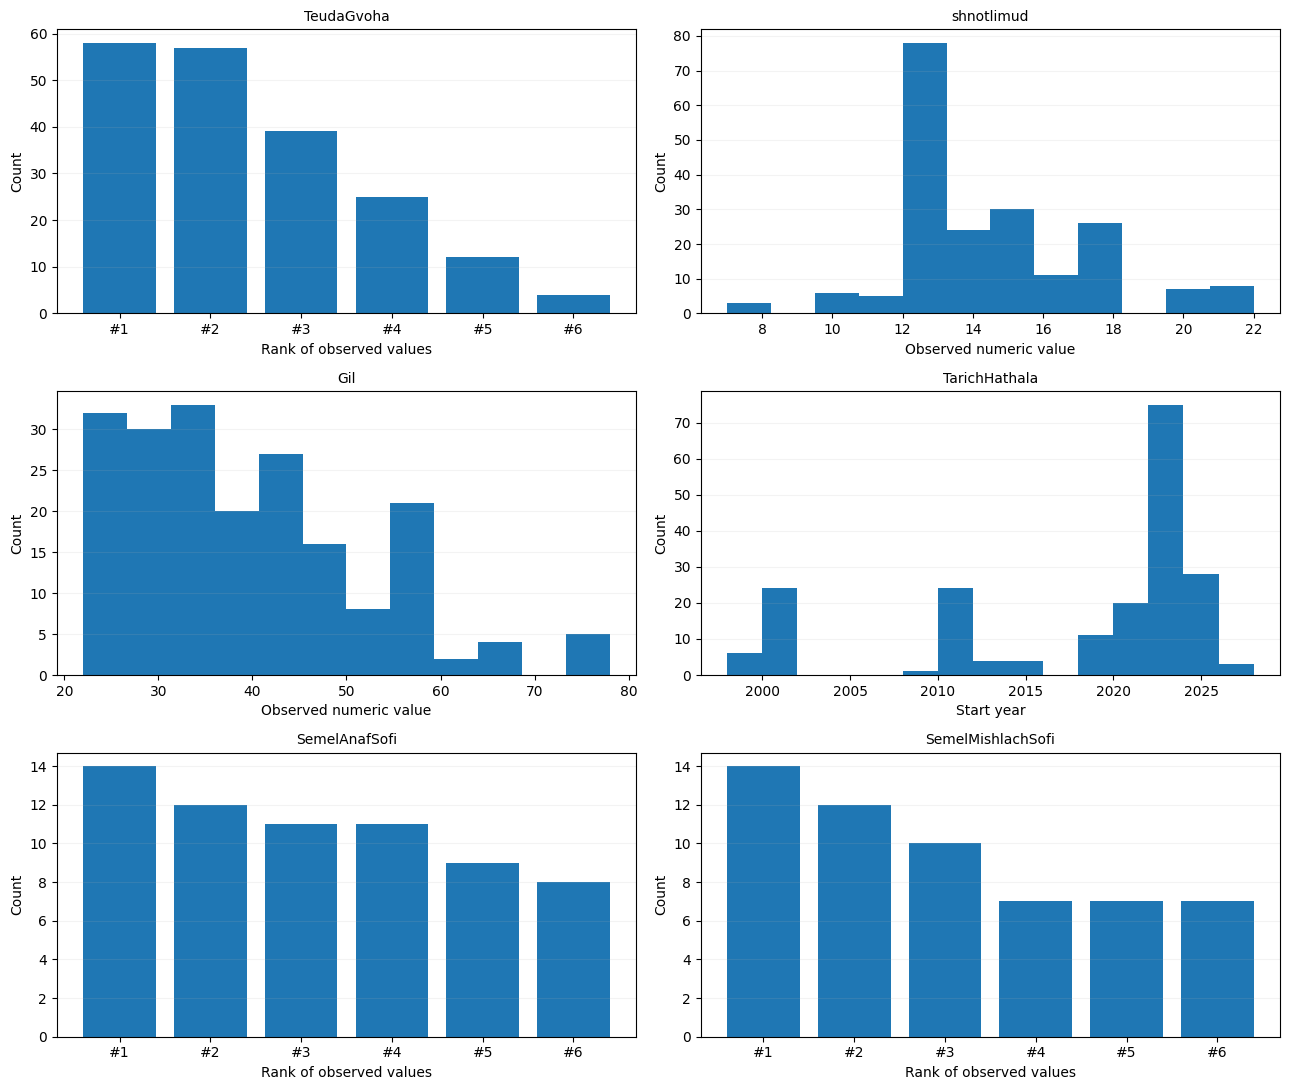

Original values for the six ranked charts:
TeudaGvoha  ::  #1: 4.0 (58) | #2: 3.0 (57) | #3: 6.0 (39) | #4: 5.0 (25) | #5: 2.0 (12) | #6: 7.0 (4)
shnotlimud  ::  #1: 12.0 (53) | #2: 15.0 (30) | #3: 13.0 (25) | #4: 14.0 (24) | #5: 18.0 (16) | #6: 16.0 (11)
Gil  ::  #1: 25.0 (16) | #2: 55.0 (15) | #3: 31.0 (15) | #4: 32.0 (15) | #5: 35.0 (14) | #6: 42.0 (10)
TarichHathala  ::  #1: 2022-07-01 (15) | #2: 2024-07-31 (14) | #3: 2022-12-01 (9) | #4: 2011-11-01 (8) | #5: 2022-04-01 (8) | #6: 2000-07-15 (8)
SemelAnafSofi  ::  #1: 5610 (14) | #2: 6201 (12) | #3: 8411 (11) | #4: 6419 (11) | #5: 5510 (9) | #6: 4711 (8)
SemelMishlachSofi  ::  #1: 5223 (14) | #2: 9112 (12) | #3: 2512 (10) | #4: 2511 (7) | #5: 5414 (7) | #6: 5412 (7)


In [5]:
def plot_field(name, ax):
    values=survey[name]
    if name=='ID':
        ax.plot(range(1,len(values)+1),pd.to_numeric(values))
        ax.set(xlabel='Survey record order',ylabel='ID')
    elif name in ['Gil','shnotlimud']:
        x=pd.to_numeric(values,errors='coerce').dropna()
        ax.hist(x,bins=min(12,x.nunique()))
        ax.set(xlabel='Observed numeric value',ylabel='Count')
    elif name=='TarichHathala':
        x=pd.to_datetime(values,errors='coerce').dt.year.dropna()
        ax.hist(x,bins=np.arange(x.min()-1,x.max()+3,2))
        ax.set(xlabel='Start year',ylabel='Count')
    else:
        top=categorical_values(name).value_counts().head(6)
        ax.bar(range(1,len(top)+1),top.values)
        ax.set_xticks(range(1,len(top)+1),labels=[f'#{i}' for i in range(1,len(top)+1)])
        ax.set(xlabel='Rank of observed values',ylabel='Count')
    ax.set_title(name,fontsize=10)
    ax.grid(axis='y',alpha=.15)

for offset in range(0,len(survey.columns),6):
    fields=list(survey.columns[offset:offset+6])
    fig,axes=plt.subplots(3,2,figsize=(13,11))
    for axis,field in zip(axes.flatten(),fields):plot_field(field,axis)
    plt.tight_layout();plt.show()
    print('Original values for the six ranked charts:')
    for field in fields:
        most=categorical_values(field).value_counts().head(6)
        print(field,' :: ',' | '.join(f'#{i}: {v} ({n})'
              for i,(v,n) in enumerate(most.items(),1)))

## 5. תקינות מבנית לכל שדה רלוונטי — כולל תלות בין עמודות
**טווחים לפי Metadata:** `MenahelEtMi` יכול לקבל 1–3; `MaamadAvoda` 1–7; `MakorSachar` 1–4; `TeudaGvoha` 1–9. קודים תקינים שאינם מופיעים בסימולציה אינם שגיאה. `shnotlimud` הוא משתנה מספרי נצפה בטווח 7–22, והגיל 22–78. 

**שדה מותנה:** `MakorSachar` אמור להיות מלא **רק אם** `MaamadAvoda` הוא 1 או 5. מציגים 9 רשומות המפרות תנאי זה. אין למחוק או לשנות את המקור, אלא להציג חריגה ולסמן ערך ״לא ישים״ בייצוג המודל.

**קודים סופיים:** קודים המכילים X הם סימול חלקי. סמלי ענף בני שלוש ספרות אינם מומרים אוטומטית לארבע ספרות, מפני שלא ניתן לשחזר בבטחה אפס שהוסר בקובץ Excel. תאריך תחילת התפקיד נבדק כתאריך, בלי לחשב ותק מועד סקר שאינו מצוי בקובץ.

MenahelEtMi | metadata-domain violations: []
MaamadAvoda | metadata-domain violations: []
MakorSachar | metadata-domain violations: []
TeudaGvoha | metadata-domain violations: []
Salary values outside stated applicability: 9
Missing salary among eligible statuses: 0


,ID,MaamadAvoda,MakorSachar
33,34,4.0,4.0
48,49,4.0,1.0
111,112,4.0,1.0
139,140,4.0,1.0
165,166,4.0,1.0
175,176,4.0,1.0
186,187,4.0,1.0
189,190,2.0,1.0
197,198,4.0,1.0


MakorSachar,1,2,3,4,[MISSING]
MaamadAvoda,,,,,
1,136,26,11,4,0
2,1,0,0,0,0
4,7,0,0,1,2
6,0,0,0,0,10
[MISSING],0,0,0,0,2


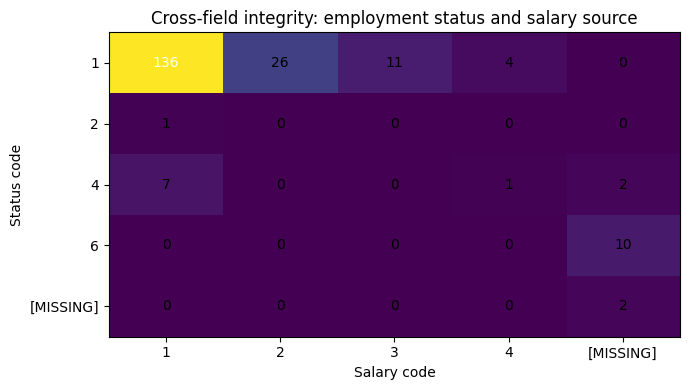

Target codes containing X: 9
Industry codes containing X: 9
Industry numeric codes of 3 digits: 5
Target distinct values: 62
IDs with three-digit industry codes: [30, 62, 93, 125, 151]
Start dates: 1999-06-06 2026-06-06 invalid: 0
SugMachlaka unresolved reference count: 8
TeurPeula unresolved reference count: 12
TeurTafkid unresolved reference count: 4
Job title textual zero: 1


In [6]:
DOMAIN={'MenahelEtMi':{1,2,3},'MaamadAvoda':set(range(1,8)),
        'MakorSachar':set(range(1,5)),'TeudaGvoha':set(range(1,10))}
for field,allowed in DOMAIN.items():
    s=pd.to_numeric(survey[field],errors='coerce').dropna().astype(int)
    problems=sorted(set(s)-allowed)
    print(field,'| metadata-domain violations:',problems)
    assert not problems
status=pd.to_numeric(survey['MaamadAvoda'],errors='coerce')
salary=pd.to_numeric(survey['MakorSachar'],errors='coerce')
ineligible_salary = status.notna() & ~status.isin([1,5]) & salary.notna()
missing_eligible_salary = status.isin([1,5]) & salary.isna()
print('Salary values outside stated applicability:',int(ineligible_salary.sum()))
print('Missing salary among eligible statuses:',int(missing_eligible_salary.sum()))
assert int(ineligible_salary.sum()) == 9 and int(missing_eligible_salary.sum()) == 0
display(survey.loc[ineligible_salary,['ID','MaamadAvoda','MakorSachar']])

def code_str(v):return '[MISSING]' if pd.isna(v) else str(int(v))
ct=pd.crosstab(status.map(code_str),salary.map(code_str))
display(ct)
fig,ax=plt.subplots(figsize=(7,4))
ax.imshow(ct.values,aspect='auto')
ax.set_xticks(range(len(ct.columns)),ct.columns)
ax.set_yticks(range(len(ct.index)),ct.index)
ax.set(xlabel='Salary code',ylabel='Status code',title='Cross-field integrity: employment status and salary source')
for i in range(ct.shape[0]):
 for j in range(ct.shape[1]):ax.text(j,i,str(ct.iloc[i,j]),ha='center',va='center',color='white' if ct.iloc[i,j]>60 else 'black')
plt.tight_layout();plt.show()

job_codes=survey['SemelMishlachSofi'].astype('string').str.strip()
industry_codes=survey['SemelAnafSofi'].astype('string').str.strip()
partial=job_codes.str.contains('X',case=False,regex=False,na=False)
ind_partial=industry_codes.str.contains('X',case=False,regex=False,na=False)
three_digit=industry_codes.str.fullmatch(r'\d{3}',na=False)
print('Target codes containing X:',int(partial.sum()))
print('Industry codes containing X:',int(ind_partial.sum()))
print('Industry numeric codes of 3 digits:',int(three_digit.sum()))
print('Target distinct values:',job_codes.nunique())
assert (int(partial.sum()),int(ind_partial.sum()),int(three_digit.sum())) == (9,9,5)
print('IDs with three-digit industry codes:',survey.loc[three_digit,'ID'].tolist())
dates=pd.to_datetime(survey['TarichHathala'],errors='coerce')
print('Start dates:',dates.min().date(),dates.max().date(),'invalid:',dates.isna().sum())
assert dates.notna().all()
for f in ['SugMachlaka','TeurPeula','TeurTafkid']:
 s=survey[f].astype('string').str.strip()
 print(f,'unresolved reference count:',int(s.isin(['כנ"ל','כנ״ל']).sum()))
print('Job title textual zero:',int((survey['TeurTafkid'].astype('string').str.strip()=='0').sum()))

## 6. כפילויות ותוויות סותרות
הקובץ מזהה כל שורה באמצעות `ID`, אך **אינו מכיל מזהה משתתף לאורך שידורים מרובים**. כדי לצמצם זליגה בין רשומות מקצועיות זהות מגדירים חתימה מנורמלת של 7 שדות תיאוריים, כולל מקום העבודה. זהו קירוב בלבד, לא הוכחה ששורות השייכות לאותה חתימה הן אותו משתתף. זיהוי כפילויות מחייב גם דיווח על קודי יעד סותרים, ולא רק מחיקה או השמטה שלהם.

Number of description groups: 137
Repeated description groups: 40
Rows belonging to a repeated group: 103
Groups containing different target codes: 1


,ID,ShemAvoda,EzoAvoda,SemelMishlachSofi
1,2,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3311
32,33,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211
64,65,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211
95,96,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211


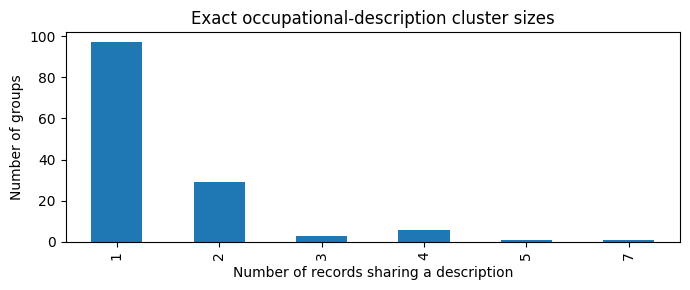

In [7]:
GROUP_FIELDS=['ShemAvoda','SugAvoda','ShemMachlaka','SugMachlaka',
              'EzoAvoda','TeurPeula','TeurTafkid']
def norm_group(v):
    if pd.isna(v):return ''
    return ' '.join(re.sub(r'[^\w\u0590-\u05FF]+',' ',str(v).lower()).split())
def group_key(frame):
    return frame[GROUP_FIELDS].apply(lambda row:'|'.join(norm_group(row[c]) for c in GROUP_FIELDS),axis=1)
groups_all=group_key(survey)
group_sizes=groups_all.value_counts()
conflicts=(survey.assign(group=groups_all).groupby('group')['SemelMishlachSofi']
           .nunique().loc[lambda s:s>1])
print('Number of description groups:',len(group_sizes))
print('Repeated description groups:',int((group_sizes>1).sum()))
print('Rows belonging to a repeated group:',int(group_sizes.loc[group_sizes>1].sum()))
print('Groups containing different target codes:',len(conflicts))
display(survey.loc[groups_all.isin(conflicts.index),
                 ['ID','ShemAvoda','EzoAvoda','SemelMishlachSofi']])
assert len(conflicts)==1
fig,ax=plt.subplots(figsize=(7,3))
group_sizes.value_counts().sort_index().plot.bar(ax=ax)
ax.set(xlabel='Number of records sharing a description',ylabel='Number of groups',
       title='Exact occupational-description cluster sizes')
plt.tight_layout();plt.show()

## 7. יצירת מאפיינים — החלטה מנומקת, לכל עמודה
**תיאור מקצועי למודל:** `SugAvoda`, `ShemMachlaka`, `SugMachlaka`, `EzoAvoda`, `TeurPeula`, `TeurTafkid`. כל שדה מסומן בשמו, כך שתיאור פעולות המשתתף לא יוחלף בטעות בפעילות הארגון. וקטוריזציה בעזרת `TfidfVectorizer(analyzer='char')` מאפשרת להתמודד עם מילים קצרות, כתיב משתנה ושילוב עברית ואנגלית ללא מחלק מילים הדורש תלות נוספת.

**קטגוריות למודל:** `MenahelEtMi`, `MaamadAvoda`, `MakorSachar`, `TeudaGvoha` מקודדות כקטגוריות עם `OneHotEncoder`, כולל סמני חסר. הטיפול בשכר מותנה במעמד. חסר בניהול אינו מתורגם ל״לא מנהל״, ובתעודה הקודים אינם מניחים דירוג לינארי.

**מספרי למודל:** `shnotlimud` בלבד. החציון והתקנון נלמדים רק מנתוני האימון בתוך `Pipeline`.

**לא במודל הראשי:** `ID` (מזהה), `YeshuvAvoda` (פרוקסי גאוגרפי), `ShemAvoda` (שינון מעסיק), `Gil` (פרוקסי גיל), `TarichHathala` (חסר מועד סקר להשוואה), `SemelAnafSofi` (סמל סופי שזמינותו לא הוכחה), `SemelMishlachSofi` (יעד). שדות אלה **כן עוברים אבחון ובקרת איכות**.

**טיפול באי-ידיעה:** ״כנ״ל״ מסומן `__unresolved_reference__` ולא מורחב על סמך שורה קודמת; ״חסוי״ מסומן `__withheld__`; המחרוזת `0` בתואר המשרה מסומנת `__invalid_zero__`. אין שינוי בנתוני המקור. לביצוע בדיקות הוגנות וניתוח השפעת מאפיינים נדרשים נתוני אמת, ולא ניתן להכריע כאן אם כל תכונה אכן בטוחה או מועילה.

In [8]:
TEXT_COLUMNS=['SugAvoda','ShemMachlaka','SugMachlaka',
              'EzoAvoda','TeurPeula','TeurTafkid']
CAT_COLUMNS=['MenahelEtMi','MaamadAvoda','MakorSachar','TeudaGvoha']
NUM_COLUMNS=['shnotlimud']
EXCLUDED=['ID','YeshuvAvoda','ShemAvoda','Gil','TarichHathala','SemelAnafSofi','SemelMishlachSofi']
assert set(TEXT_COLUMNS+CAT_COLUMNS+NUM_COLUMNS+EXCLUDED)==set(survey.columns)
assert len(TEXT_COLUMNS+CAT_COLUMNS+NUM_COLUMNS+EXCLUDED)==18

def text_value(v):
    if pd.isna(v) or not str(v).strip():return '__missing__'
    val=re.sub(r'\s+',' ',str(v).strip())
    if val in {'כנ"ל','כנ״ל'}:return '__unresolved_reference__'
    if val=='חסוי':return '__withheld__'
    if val=='0':return '__invalid_zero__'
    return val

def model_features(frame):
    X=pd.DataFrame(index=frame.index)
    X['job_text']=frame.apply(lambda row:' '.join(f'{c}={text_value(row[c])};' for c in TEXT_COLUMNS),axis=1)
    for c in CAT_COLUMNS:
        X[c]=frame[c].map(lambda v: 'missing' if pd.isna(v) else str(int(v)))
    status=X['MaamadAvoda']
    X['MakorSachar']=np.where(status.isin(['1','5']),X['MakorSachar'],
                         np.where(status=='missing','status_unknown','not_applicable'))
    X['shnotlimud']=pd.to_numeric(frame['shnotlimud'],errors='coerce')
    return X

model_inputs=model_features(survey)
display(model_inputs.head(5))
print('Numerical missing — filled later using TRAINING ONLY:',model_inputs['shnotlimud'].isna().sum())

,job_text,MenahelEtMi,MaamadAvoda,MakorSachar,TeudaGvoha,shnotlimud
0,"SugAvoda=איסוף, עיבוד ופרסום נתונים; ShemMachl...",3,1,1,6,22.0
1,SugAvoda=טיפול בחולים; ShemMachlaka=רדיואתרפיה...,missing,1,1,6,22.0
2,SugAvoda=מתן שירות למשתמשים באתר GOV; ShemMach...,missing,1,1,5,15.0
3,SugAvoda=בית ספר יסודי; ShemMachlaka=שמירה; Su...,missing,1,2,3,12.0
4,SugAvoda=מטפל בקשיש במשפחה; ShemMachlaka=__mis...,missing,1,1,4,14.0


Numerical missing — filled later using TRAINING ONLY: 2


## 8. הפרדת רשומות, אימון והערכה
`SemelMishlachSofi` המכיל X אינו תווית מלאה ולא נכלל באימון או במדדי נכונות. עבור 191 הרשומות בעלות סמל מלא מבצעים `GroupShuffleSplit`, כך שרשומות עם אותה חתימת תיאור לא יופיעו משני צדי החלוקה. החתימה אינה מזהה משתתף אמיתי ולכן אינה מונעת בהכרח זליגה בין דיווחים מנוסחים אחרת.

האימון מתבצע ב-`Pipeline` המשלב טקסט, קטגוריות ומספרים. אין `fit` או למידת חציון/אוצר מילים על קבוצת הבדיקה. נציג קו בסיס `DummyClassifier` באותה חלוקה. **מדדי החיזוי הם בדיקת תקינות טכנית של התהליך על נתונים סינתטיים, לא מסקנה על הצלחת הפתרון.**

In [9]:
partial_mask=survey['SemelMishlachSofi'].astype('string').str.contains('X',case=False,regex=False,na=False)
complete=survey.loc[~partial_mask].copy(); partial_rows=survey.loc[partial_mask].copy()
X=model_features(complete); y=complete['SemelMishlachSofi'].astype(str)
groups=group_key(complete)
assert len(complete)==191 and len(partial_rows)==9
train_pos,test_pos=next(GroupShuffleSplit(n_splits=1,test_size=.22,random_state=SEED).split(X,y,groups))
assert not set(groups.iloc[train_pos]).intersection(groups.iloc[test_pos])
X_train,X_test=X.iloc[train_pos],X.iloc[test_pos]
y_train,y_test=y.iloc[train_pos],y.iloc[test_pos]
unseen=~y_test.isin(set(y_train))
print('Train rows',len(X_train),'| grouped holdout rows',len(X_test))
print('Complete classes:',y.nunique(),'| train classes:',y_train.nunique(),
      '| test rows with unseen target classes:',int(unseen.sum()))

pipeline=Pipeline([
    ('preprocess',ColumnTransformer([
      ('text',TfidfVectorizer(analyzer='char',ngram_range=(2,5),max_features=10000,sublinear_tf=True),'job_text'),
      ('nominal',OneHotEncoder(handle_unknown='ignore'),CAT_COLUMNS),
      ('numeric',Pipeline([('median_train_only',SimpleImputer(strategy='median')),
                           ('standard_train_only',StandardScaler())]),NUM_COLUMNS)
    ],sparse_threshold=1.0)),
    ('classifier',LogisticRegression(C=2.0,max_iter=1200,solver='lbfgs'))
])
baseline=DummyClassifier(strategy='most_frequent')
pipeline.fit(X_train,y_train)
baseline.fit(X_train,y_train)
model_pred=pipeline.predict(X_test)
baseline_pred=baseline.predict(X_test)
model_scores=pipeline.predict_proba(X_test)

def score_row(name,ypred):
    return {'model':name, 'accuracy':accuracy_score(y_test,ypred),
            'macro_F1':f1_score(y_test,ypred,average='macro',zero_division=0),
            'weighted_F1':f1_score(y_test,ypred,average='weighted',zero_division=0)}
metrics=pd.DataFrame([score_row('Majority-class baseline',baseline_pred),
                      score_row('TF-IDF + mixed-type logistic regression',model_pred)])
display(metrics.round(3))
print('Unseen full-code classes in held-out data:',sorted(set(y_test)-set(y_train)))
print('Interpretation: synthetic data only; holdout contains rare and unseen classes.')

Train rows 149 | grouped holdout rows 42
Complete classes: 59 | train classes: 52 | test rows with unseen target classes: 8


,model,accuracy,macro_F1,weighted_F1
0,Majority-class baseline,0.00,0.000,0.00
1,TF-IDF + mixed-type logistic regression,0.69,0.439,0.65


Unseen full-code classes in held-out data: ['1212', '2330', '2412', '3312', '3323', '3334', '5222']
Interpretation: synthetic data only; holdout contains rare and unseen classes.


## 9. תוצאות החיזוי
כל תחזית כוללת מזהה, סמל מקורי, סמל חזוי, התאמה לתווית שנמסרה, אינדיקציה לכך שהמחלקה נראתה באימון, וערך מודל גולמי בלתי מכויל. **אין להשתמש ב-`predict_proba` כסיכוי מאומת או כסף אוטומטי**, מפני שאין ערכת כיול עצמאית ונתוני אמת יציבים. גם קוד מלא בחיזוי וגם הצעה לקוד X מחייבים סקירת סמלן בשלב הדגמה זה.

In [10]:
holdout_predictions=pd.DataFrame({
    'ID':complete.iloc[test_pos]['ID'].to_numpy(),
    'observed_code':y_test.to_numpy(),
    'predicted_code':model_pred,
    'matches_given_code':model_pred==y_test.to_numpy(),
    'class_seen_in_train':(~unseen).to_numpy(),
    'uncalibrated_model_score':np.round(model_scores.max(axis=1),3),
    'action':'human_review'
})
display(holdout_predictions)
print('Full held-out prediction count:',len(holdout_predictions))
print(classification_report(y_test,model_pred,zero_division=0))

X_partial=model_features(partial_rows)
partial_proposals=pd.DataFrame({
    'ID':partial_rows['ID'].to_numpy(),
    'original_partial_code':partial_rows['SemelMishlachSofi'].astype(str).to_numpy(),
    'suggested_code':pipeline.predict(X_partial),
    'uncalibrated_model_score':np.round(pipeline.predict_proba(X_partial).max(axis=1),3),
    'action':'human_review_no_full_target'
})
display(partial_proposals)
assert len(partial_proposals)==9

,ID,observed_code,predicted_code,matches_given_code,class_seen_in_train,uncalibrated_model_score,action
0,12,2631,2631,True,True,0.543,human_review
1,13,5131,5223,False,True,0.159,human_review
2,16,5223,5223,True,True,0.454,human_review
3,25,3323,2655,False,False,0.162,human_review
4,27,9112,9112,True,True,0.352,human_review
5,28,5120,5120,True,True,0.334,human_review
6,36,5322,5322,True,True,0.249,human_review
7,38,3122,3122,True,True,0.292,human_review
8,41,2514,2514,True,True,0.189,human_review
9,48,5223,5223,True,True,0.454,human_review


Full held-out prediction count: 42
              precision    recall  f1-score   support

        1212       0.00      0.00      0.00         1
        2120       0.00      0.00      0.00         0
        2330       0.00      0.00      0.00         1
        2342       1.00      1.00      1.00         1
        2412       0.00      0.00      0.00         1
        2423       0.00      0.00      0.00         0
        2511       0.00      0.00      0.00         2
        2514       0.33      1.00      0.50         1
        2631       1.00      1.00      1.00         1
        2635       1.00      1.00      1.00         1
        2655       0.00      0.00      0.00         0
        3122       1.00      1.00      1.00         2
        3312       0.00      0.00      0.00         1
        3323       0.00      0.00      0.00         2
        3334       0.00      0.00      0.00         1
        3512       0.00      0.00      0.00         1
        5120       1.00      1.00      1.00   

,ID,original_partial_code,suggested_code,uncalibrated_model_score,action
0,18,1XXX,2120,0.109,human_review_no_full_target
1,45,XXXX,5142,0.102,human_review_no_full_target
2,50,1XXX,2120,0.105,human_review_no_full_target
3,81,1XXX,2120,0.109,human_review_no_full_target
4,108,XXXX,5142,0.102,human_review_no_full_target
5,113,1XXX,2120,0.105,human_review_no_full_target
6,142,XXXX,7412,0.201,human_review_no_full_target
7,165,335X,3354,0.152,human_review_no_full_target
8,193,XXXX,5223,0.313,human_review_no_full_target


## 10. תובנות, מגבלות והמשך הטמעה
**המסקנה העיקרית:** תהליך מקצועי מחייב טיפול מפורש בשדות לפני אימון, ולא בחירה אוטומטית של כל העמודות. מצאנו 9 ערכי מקור שכר המפרים תנאי מילוי, קודים חלקיים, סמלי ענף תלת-ספרתיים, היעדר תיאור מלא בחלק מהשדות ותיאור מקצועי זהה עם תוויות סותרות. אין תוויות זהב לקביעת נכונות מחלוקות הסמלנים.

**סייגי האימות:** `ID` הוא מספר רץ, לא מזהה נסקר; תיאורים סמנטיים שונים יכולים לייצג אותו משתתף; מחלקות רבות נדירות וחלקן נעדרות מהאימון. מדדי accuracy ו-F1 כאן אינם אומדנים תקפים לאוכלוסיית אמת, בדיוק כפי שמצהירה המטלה שהחיזוי בסימולציה אינו המטרה.

**מסלול הטמעה מבוקר:**
1. הגדרת מזהה משתתף וגרסת שאלון, מועד כל שידור, זמינות כל עמודה בזמן אמת ותנאי התחולה שלה.
2. ביסוס מדגם תוויות מוסכמות בהכרעה בין סמלנים, כולל הסבר לקודי X, ומדידת איכות התווית עצמה.
3. חלוקה לפי משתתף וזמן, בדיקת כיתות נדירות וניסוי השוואתי לדגמי בסיס ולתכונות לא-סיבתיות.
4. כיול הסתברויות על נתונים עצמאיים, מנגנון הימנעות, והפניית מקרי אי-ודאות לסמלן.
5. ניסוי הדרגתי עם תיעוד החלטות, ניטור drift ובקרות הוגנות, בטרם אוטומציה.

**ביסוס ממקורות חיצוניים:**
- [scikit-learn: Data leakage and pipelines](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn: GroupShuffleSplit (שיעור קבוצות, לא שורות)](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)
- [scikit-learn: ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)
- [scikit-learn: TF-IDF vectorization](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html)
- [scikit-learn: Probability calibration](https://scikit-learn.org/stable/modules/calibration.html)

היישום נכתב עבור המטלה ולא הועתק מ-[Ensembles](https://github.com/OrShulrufer/Ensembles). המאגר הקודם שימש לבחינת עקרונות הפרדת אחריות ובדיקות בלבד.